# Projet ML kaggle : Give me some credits

## Remise en contexte : détailler + PROBLEMATIQUE

## 1. La mise en route
### 1.A Import des modules

In [1]:
# Imports des modules nécessaires

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split

### 1.B Import des données

In [6]:
# Imports du jeu de données cs-training.csv

df = pd.read_csv("cs-training.csv", index_col=0)
print("Taille du jeu de données :", df.shape)

# On regarde la proportion respectivement de 0 et 1 dans la colonne cible SeriousDlqin2yrs
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

Taille du jeu de données : (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


### 1.C Préparation des des données d'entraînement et de test

In [7]:
# Découpage du jeu de données cs-training.csv en un jeu d'entraînement et un jeu de test

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
0.06684166666666666 0.06683333333333333


## 2. L'exploration des données
### 2.A Description générale du jeu de données train

In [35]:
train = X_train.copy()
train["SeriousDlqin2yrs"] = y_train

print("\nStructure des données de train : \n------------------")
train.info()                    # On repère notamment les valeurs manquantes et le type des variables
print("\nQuelques statistiques descriptives : \n------------------")
train.describe().T


Structure des données de train : 
------------------
<class 'pandas.core.frame.DataFrame'>
Index: 120000 entries, 57837 to 80531
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 1   age                                   120000 non-null  int64  
 2   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 3   DebtRatio                             120000 non-null  float64
 4   MonthlyIncome                         96325 non-null   float64
 5   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 6   NumberOfTimes90DaysLate               120000 non-null  int64  
 7   NumberRealEstateLoansOrLines          120000 non-null  int64  
 8   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 9   NumberOfDependents                    116872 non-null  float64
 10  SeriousDlqin2yrs

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,120000.0,6.128916,253.361490,0.0,0.029593,0.153318,0.557832,50708.0
age,120000.0,52.287842,14.771274,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.420075,4.182138,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,352.271245,2093.709509,0.0,0.175330,0.366194,0.860833,329664.0
MonthlyIncome,96325.0,6651.507345,14541.181413,0.0,3400.000000,5390.000000,8238.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.465692,5.161693,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.264942,4.158242,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.018167,1.133055,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.239858,4.144569,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,116872.0,0.757333,1.115337,0.0,0.000000,0.000000,1.000000,20.0


### 2.B Description des valeurs manquantes

In [31]:
print("\nProportion de valeurs manquantes dans chaque variable du jeu de données train : \n------------------")
missing = train.isna().mean().sort_values(ascending=False) * 100
print(missing[missing > 0].round(2))

# On regarde la proportion de défauts de paiement en fonction des variables avec valeurs manquantes
print("\nLes manquants sont-ils corrélés avec la variable cible ? \n------------------")
for i in ["MonthlyIncome", "NumberOfDependents"]:
    taux = train.groupby(train[i].isna())["SeriousDlqin2yrs"].mean()
    print(i, "\n", taux.rename({False: "renseigné", True: "manquant"}), "\n")



Proportion de valeurs manquantes dans chaque variable du jeu de données train : 
------------------
MonthlyIncome         19.73
NumberOfDependents     2.61
dtype: float64

Les manquants sont-ils corrélés avec la variable cible ? 
------------------
MonthlyIncome 
 MonthlyIncome
renseigné    0.069577
manquant     0.055713
Name: SeriousDlqin2yrs, dtype: float64 

NumberOfDependents 
 NumberOfDependents
renseigné    0.067450
manquant     0.044118
Name: SeriousDlqin2yrs, dtype: float64 



<div style="color: #0099ff;">

##### Ce qu'on observe : 2 variables contiennent des valeurs manquantes
- Près de 20% des personnes n'ont pas renseigné leur revenu mensuel (MonthlyIncome)
- On a 2,6% de valeurs manquantes sur le nombre de personnes à charge (NumberOfDependents)

##### Comment interpréter les valeurs manquantes ?
On calcule le taux de défaut de paiement dans chaque groupe qui contient des manquants.
On remarque cependant qu'on ne peut pas conclure sur l'association entre l'absence de revenus indiquée et un potentiel défaut de paiement.

</div>


### 2.C Analyse des valeurs suspectes

In [32]:
print("Âge = 0 :", (train["age"] == 0).sum())
print("Utilisation du crédit > 1 :", (train["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("DebtRatio > 1 :", (train["DebtRatio"] > 1).sum())

retards = ["NumberOfTime30-59DaysPastDueNotWorse",
           "NumberOfTimes90DaysLate",
           "NumberOfTime60-89DaysPastDueNotWorse"]
for c in retards:
    print(c, train[c].value_counts().sort_index().tail(6).to_dict())

print("Doublons :", train.duplicated().sum())

Âge = 0 : 1
Utilisation du crédit > 1 : 2640
DebtRatio > 1 : 27987
NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 2, 13: 1, 96: 2, 98: 212}
NumberOfTimes90DaysLate {13: 3, 14: 2, 15: 2, 17: 1, 96: 2, 98: 212}
NumberOfTime60-89DaysPastDueNotWorse {7: 8, 8: 1, 9: 1, 11: 1, 96: 2, 98: 212}
Doublons : 437


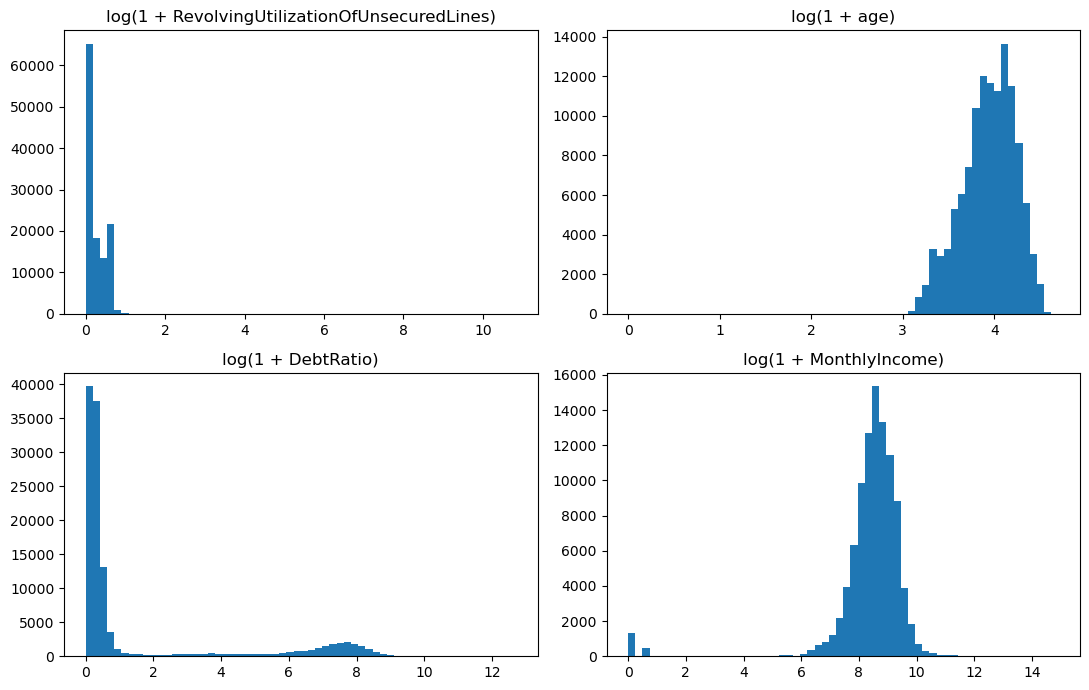

In [36]:
cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(np.log1p(train[c].dropna().clip(lower=0)), bins=60)
    ax.set_title(f"log(1 + {c})")
plt.tight_layout()
plt.show()

In [34]:
train["tranche_age"] = pd.cut(train["age"], bins=[0, 25, 35, 45, 55, 65, 120])
print(train.groupby("tranche_age", observed=True)["SeriousDlqin2yrs"].agg(["mean", "count"]))

corr = train.drop(columns="tranche_age").corr(method="spearman")["SeriousDlqin2yrs"]
print(corr.drop("SeriousDlqin2yrs").sort_values())

                 mean  count
tranche_age                 
(0, 25]      0.109980   2455
(25, 35]     0.108688  14721
(35, 45]     0.088126  23875
(45, 55]     0.076136  29329
(55, 65]     0.046733  26769
(65, 120]    0.024639  22850
age                                    -0.113887
MonthlyIncome                          -0.065582
NumberOfOpenCreditLinesAndLoans        -0.041060
NumberRealEstateLoansOrLines           -0.033924
DebtRatio                               0.019206
NumberOfDependents                      0.046135
RevolvingUtilizationOfUnsecuredLines    0.240463
NumberOfTime30-59DaysPastDueNotWorse    0.254833
NumberOfTime60-89DaysPastDueNotWorse    0.278078
NumberOfTimes90DaysLate                 0.343674
Name: SeriousDlqin2yrs, dtype: float64
